In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set style for plots
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
class FitnessTracker:
    def __init__(self, filepath="fitness_activities.csv"):
        self.filepath = filepath
        self.df = self.load_data()
        
    def load_data(self):
        """Load existing activity data from CSV into a Pandas DataFrame, or create empty one if not exists."""
        if os.path.exists(self.filepath):
            df = pd.read_csv(self.filepath)
            # Ensure proper column types
            if 'Date' in df.columns:
                df['Date'] = pd.to_datetime(df['Date']).dt.date
            return df
        else:
            return pd.DataFrame(columns=['Date', 'Activity Type', 'Duration (Minutes)', 'Calories Burned'])

    def save_data(self):
        """Save current DataFrame back to CSV."""
        self.df.to_csv(self.filepath, index=False)

    def log_activity(self, date, activity_type, duration, calories):
        """Validates and logs a new fitness activity into the dataset."""
        # Validation checks using control structures
        if not activity_type.strip():
            print("Error: Activity type cannot be empty.")
            return False
        
        try:
            duration = float(duration)
            calories = float(calories)
            if duration <= 0 or calories <= 0:
                print("Error: Duration and Calories burned must be positive numbers.")
                return False
        except ValueError:
            print("Error: Duration and Calories must be valid numeric values.")
            return False

        # Add new row
        new_row = {
            'Date': pd.to_datetime(date).date(),
            'Activity Type': activity_type.capitalize(),
            'Duration (Minutes)': duration,
            'Calories Burned': calories
        }
        
        # Append using pandas concat
        self.df = pd.concat([self.df, pd.DataFrame([new_row])], ignore_index=True)
        self.save_data()
        print(f"Successfully logged: {activity_type} on {date}!")
        return True

    def calculate_metrics(self):
        """Calculates total calories burned, average duration, and activity frequency using NumPy & Pandas."""
        if self.df.empty:
            print("No data available to calculate metrics.")
            return None
        
        total_calories = np.sum(self.df['Calories Burned'].values)
        avg_duration = np.mean(self.df['Duration (Minutes)'].values)
        total_activities = len(self.df)
        
        # Computed Metric example: Calories per Minute
        self.df['Calories per Minute'] = self.df['Calories Burned'] / self.df['Duration (Minutes)']
        
        metrics = {
            "Total Activities": total_activities,
            "Total Calories Burned": total_calories,
            "Average Duration (Minutes)": round(avg_duration, 2),
            "Average Calories per Minute": round(np.mean(self.df['Calories per Minute'].values), 2)
        }
        return metrics

    def filter_activities(self, activity_type=None, start_date=None, end_date=None):
        """Filters activities based on type or date range."""
        filtered_df = self.df.copy()
        
        if activity_type:
            filtered_df = filtered_df[filtered_df['Activity Type'].str.lower() == activity_type.lower()]
            
        if start_date and end_date:
            filtered_df['Date'] = pd.to_datetime(filtered_df['Date'])
            start_date = pd.to_datetime(start_date)
            end_date = pd.to_datetime(end_date)
            filtered_df = filtered_df[(filtered_df['Date'] >= start_date) & (filtered_df['Date'] <= end_date)]
            
        return filtered_df

    def generate_report(self):
        """Summarizes fitness data for user review."""
        print("--- Fitness Summary Report ---")
        metrics = self.calculate_metrics()
        if metrics:
            for k, v in metrics.items():
                print(f"{k}: {v}")
        print("\nRecent Activity Logs:")
        print(self.df.tail())

In [6]:
# Initialize the tracker object
tracker = FitnessTracker()

# Display summary report and calculated metrics
tracker.generate_report()

--- Fitness Summary Report ---
No data available to calculate metrics.

Recent Activity Logs:
Empty DataFrame
Columns: [Date, Activity Type, Duration (Minutes), Calories Burned]
Index: []


In [8]:
# Example of logging a new valid activity
tracker.log_activity(date="2026-05-08", activity_type="Running", duration=35, calories=380)

# Example of testing edge case / invalid input handling
tracker.log_activity(date="2026-05-09", activity_type="Cycling", duration=-10, calories=200)

Successfully logged: Running on 2026-05-08!
Error: Duration and Calories burned must be positive numbers.


False

C:\Users\Admin\AppData\Local\Temp\ipykernel_5012\4009782778.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=activity_duration, x='Activity Type', y='Duration (Minutes)', palette='Blues_d')


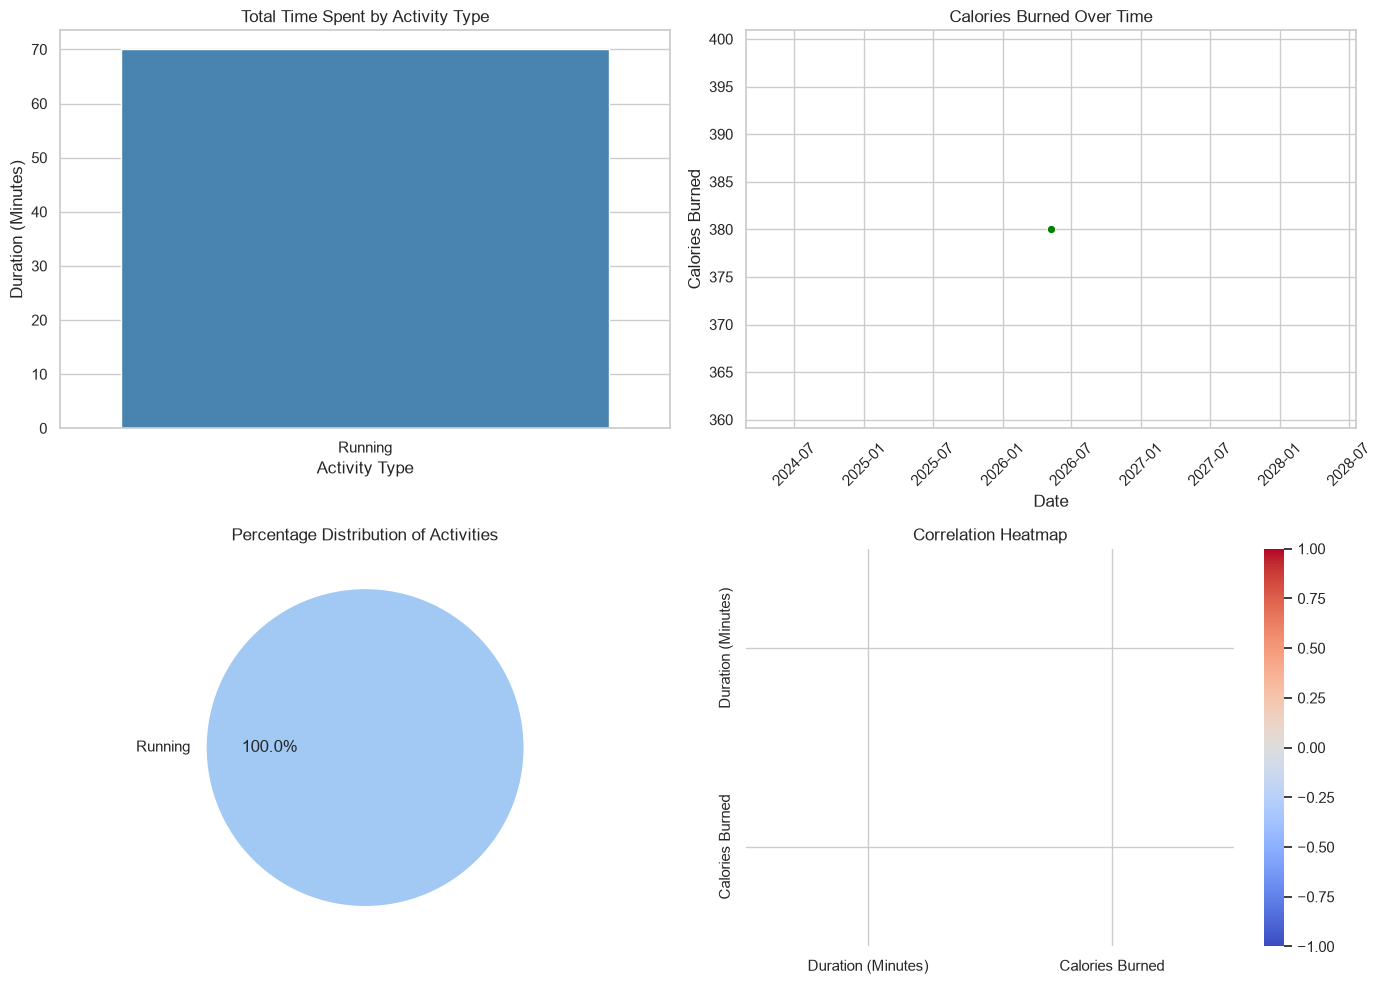

In [10]:
plt.figure(figsize=(14, 10))

# 1. Bar Chart: Time spent on each activity type
plt.subplot(2, 2, 1)
activity_duration = tracker.df.groupby('Activity Type')['Duration (Minutes)'].sum().reset_index()
sns.barplot(data=activity_duration, x='Activity Type', y='Duration (Minutes)', palette='Blues_d')
plt.title('Total Time Spent by Activity Type')
plt.xlabel('Activity Type')
plt.ylabel('Duration (Minutes)')

# 2. Line Graph: Calories burned over time
plt.subplot(2, 2, 2)
sorted_df = tracker.df.sort_values(by='Date')
sns.lineplot(data=sorted_df, x='Date', y='Calories Burned', marker='o', color='green')
plt.title('Calories Burned Over Time')
plt.xlabel('Date')
plt.ylabel('Calories Burned')
plt.xticks(rotation=45)

# 3. Pie Chart: Percentage distribution of activities
plt.subplot(2, 2, 3)
activity_counts = tracker.df['Activity Type'].value_counts()
plt.pie(activity_counts, labels=activity_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'))
plt.title('Percentage Distribution of Activities')

# 4. Heatmap: Correlation between exercise duration and calories burned
plt.subplot(2, 2, 4)
numeric_cols = tracker.df[['Duration (Minutes)', 'Calories Burned']]
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()